# 03 · Evidencia: multisemilla, comparativa, diagnóstico y persistencia

Parte 3 de 3. Mismo código que las secciones 9–14 del original.

**Requisito:** haber corrido `01` y `02`. Aquí están las 2 semillas extra (parte lenta), las tablas, todos los gráficos de diagnóstico y el `save_ensemble` final a `models/`.

In [1]:
# FIX ruta: los cuadernos viven en notebooks/ds02_ensemble pero los datos estan en la raiz.
# Se vuelve a la raiz para que archive/... y models/... resuelvan igual que en el original.
import pathlib as _pl
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
import os as _os
_os.chdir(_ROOT)
print("cwd:", _os.getcwd())
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd

import ds02_rul
from ds02_rul import calculate_nasa_score, evaluate_predictions, macro_rmse
from ds02_rul.conformal import apply_conformal, empirical_coverage, fit_conformal
from ds02_rul.data import load_ds02
from ds02_rul.features import build_windows, fit_preprocessing
from ds02_rul.model import build_champion_bilstm
from ds02_rul.persistence import build_manifest, load_ensemble, save_ensemble
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import (
    fit_meta_learners, in_sample_beta_diagnostic, meta_predict, select_beta_grouped,
)
from ds02_rul.pipeline import (
    ablation_table, make_lgbm, oof_base_predictions, run_seed, seed_summary,
)

import keras
import lightgbm as lgb
import sklearn

SEEDS = [42, 7, 123]
PRIMARY_SEED = SEEDS[0]
WINDOW_SIZE = 50
STEP_TRAIN = 3
STEP_TEST = 2

print('python  :', sys.version.split()[0])
print('keras   :', keras.__version__)
print('lightgbm:', lgb.__version__)
print('sklearn :', sklearn.__version__)
print('ds02_rul:', ds02_rul.__version__, '->', os.path.dirname(ds02_rul.__file__))


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


python  : 3.12.10
keras   : 3.15.1
lightgbm: 4.7.0
sklearn : 1.9.1
ds02_rul: 4.1.0 -> C:\Users\mikel\Desktop\Pruebas\nasa\src\ds02_rul


In [2]:
# --- utilidades de presentación: importaciones ---
# `plt` se importa aquí, no en la celda de persistencia: las funciones
# de abajo lo usan y esa celda se ejecuta después de todos los gráficos.
import matplotlib.pyplot as plt

# --- paleta y etiquetas -----------------------------------------------------
# Un color por modelo, el mismo en todos los gráficos. Así el lector reconoce
# la serie sin volver a leer la leyenda.
PALETA = {
    'LightGBM solo': '#8C8C8C',
    'BiLSTM solo': '#4C72B0',
    'Híbrido + EMA5': '#1FA098',
}
COLORES_ABLACION = {'LGBM': '#8C8C8C', 'BiLSTM': '#4C72B0', 'BiLSTM+EMA': '#1FA098'}
NOMBRE_CORTO = {'LightGBM solo': 'LightGBM', 'BiLSTM solo': 'BiLSTM'}


def nombre_corto(modelo):
    """Etiqueta corta para los ejes; no toca el nombre que usan las tablas."""
    return NOMBRE_CORTO.get(modelo, modelo)


# --- tablas -----------------------------------------------------------------
def tabla_modelos(summary, metricas=('RMSE', 'MAE', 'R2', 'NASA_Score')):
    """Una fila por modelo con 'media ± desviación' en cada métrica.

    Ordena por RMSE medio y devuelve strings: es una tabla para leer, no para
    volver a calcular. Los decimales se eligen por métrica para que el ruido de
    las últimas cifras no se confunda con una diferencia.
    """
    orden = summary.sort_values('RMSE_mean')
    filas = []
    for _, fila in orden.iterrows():
        registro = {'Modelo': fila['Modelo']}
        for metrica in metricas:
            decimales = {'R2': 4, 'NASA_Score': 1}.get(metrica, 3)
            registro[metrica] = (f"{fila[f'{metrica}_mean']:.{decimales}f}"
                                 f" ± {fila[f'{metrica}_std']:.{decimales}f}")
        filas.append(registro)
    return pd.DataFrame(filas)


def comparar_con_base(summary, base, metricas=('RMSE', 'MAE')):
    """Cuánto mejora (o empeora) cada modelo frente a la base indicada.

    El delta es la diferencia directa de medias: negativo en RMSE/MAE significa
    que se equivoca menos. La columna 'mejora %' ya viene en positivo cuando
    mejora, para poder decirla en voz alta sin cambiar de signo.
    """
    fila_base = summary.loc[summary['Modelo'] == base].iloc[0]
    filas = []
    for _, fila in summary.sort_values('RMSE_mean').iterrows():
        registro = {'Modelo': fila['Modelo'], 'frente a': base}
        for metrica in metricas:
            delta = fila[f'{metrica}_mean'] - fila_base[f'{metrica}_mean']
            registro[f'delta {metrica}'] = round(float(delta), 3)
            registro[f'mejora {metrica} %'] = round(-100 * float(delta) / float(fila_base[f'{metrica}_mean']), 1)
        filas.append(registro)
    return pd.DataFrame(filas)


def tabla_por_motor(y_real, y_pred, unidades):
    """RMSE, MAE y sesgo de cada motor de test, por separado.

    Un promedio bueno puede esconder un motor malo: si un motor concentra el
    error, el número global no describe al modelo.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    unidades = np.asarray(unidades)
    filas = []
    for unidad in sorted(np.unique(unidades).tolist()):
        mask = unidades == unidad
        error = y_pred[mask] - y_real[mask]
        filas.append({
            'Motor': int(unidad),
            'Ventanas': int(mask.sum()),
            'RMSE': round(float(np.sqrt(np.mean(error ** 2))), 3),
            'MAE': round(float(np.mean(np.abs(error))), 3),
            'Sesgo': round(float(error.mean()), 3),
        })
    return pd.DataFrame(filas)


# --- gráficos ---------------------------------------------------------------
def barras_metricas(summary, metricas=('RMSE', 'MAE', 'R2', 'NASA_Score'), figsize=(11, 7)):
    """Barras horizontales de la media, con la desviación entre semillas como error.

    La rayita es la desviación: si dos barras se diferencian menos que eso, es
    un empate y no hay que elegir por el tercer decimal.
    """
    orden = summary.sort_values('RMSE_mean')
    etiquetas = [nombre_corto(m) for m in orden['Modelo']]
    colores = [PALETA.get(m, '#999999') for m in orden['Modelo']]

    fig, axes = plt.subplots(2, 2, figsize=figsize)
    for ax, metrica in zip(axes.ravel(), metricas):
        ax.barh(etiquetas, orden[f'{metrica}_mean'].values,
                xerr=orden[f'{metrica}_std'].values, color=colores, capsize=5)
        ax.set_title(metrica)
        ax.set_xlabel('media ± desviación entre semillas')
        ax.grid(True, axis='x', ls='--', alpha=0.5)
        ax.invert_yaxis()
    fig.suptitle('Comparación de modelos sobre los motores 11/14/15', y=1.01)
    plt.tight_layout()
    plt.show()


def dispersion_por_semilla(seed_rows, metrica='RMSE', figsize=(9, 4)):
    """Un punto por semilla y una línea con la media.

    Si los puntos se abren mucho, el promedio no alcanza: hay que decir cuánto
    varía el modelo antes de declararlo ganador.
    """
    df = pd.DataFrame(seed_rows)
    modelos = [m for m in PALETA if m in set(df['Modelo'])]
    fig, ax = plt.subplots(figsize=figsize)
    for i, modelo in enumerate(modelos):
        valores = df.loc[df['Modelo'] == modelo, metrica].values
        if len(valores) == 0:
            continue
        x = np.full(len(valores), i) + np.linspace(-0.06, 0.06, len(valores))
        ax.scatter(x, valores, s=80, color=PALETA[modelo], zorder=3)
        ax.hlines(valores.mean(), i - 0.22, i + 0.22, color='black', lw=1.8)
        ax.annotate(f'{valores.mean():.3f}', (i, valores.mean()),
                    textcoords='offset points', xytext=(0, 12), ha='center')
    ax.set_xticks(range(len(modelos)))
    ax.set_xticklabels([nombre_corto(m) for m in modelos])
    ax.set_ylabel(metrica)
    ax.set_title(f'{metrica} por semilla — cada punto es una semilla, la línea es la media')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


def barras_ablacion(abl, metrica='RMSE', figsize=(11, 4.5)):
    """Barras agrupadas: una variante de la ablación por grupo, un modelo por barra.

    Responde una sola pregunta: cuánto cambia la métrica al quitar el contador
    de ciclos o al usar la línea base por motor.
    """
    tabla = abl.pivot(index='variant', columns='model', values=metrica)
    modelos = list(tabla.columns)
    posiciones = np.arange(len(tabla.index))
    ancho = 0.8 / len(modelos)

    fig, ax = plt.subplots(figsize=figsize)
    for i, modelo in enumerate(modelos):
        ax.bar(posiciones + i * ancho - 0.4 + ancho / 2, tabla[modelo].values,
               width=ancho, label=modelo,
               color=COLORES_ABLACION.get(modelo, '#999999'))
    ax.set_xticks(posiciones)
    ax.set_xticklabels([v.replace('  ', ' ') for v in tabla.index], rotation=12, ha='right')
    ax.set_ylabel(metrica)
    ax.set_title(f'{metrica} por variante de la ablación (más corta es mejor)')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    ax.legend(title='modelo')
    plt.tight_layout()
    plt.show()
    return tabla


def real_vs_predicho(y_real, y_pred, titulo, figsize=(6.5, 6)):
    """Dispersión predicción frente a realidad, con la diagonal identidad.

    Un modelo perfecto pone todos los puntos sobre la diagonal. Lo que importa
    no es el punto individual sino la forma de la nube: si se abre en abanico
    hacia la derecha, el error crece con la RUL.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_pred - y_real
    rmse = float(np.sqrt(np.mean(error ** 2)))
    mae = float(np.mean(np.abs(error)))
    r2 = float(1 - np.sum(error ** 2) / np.sum((y_real - y_real.mean()) ** 2))
    limite = float(max(y_real.max(), y_pred.max()) * 1.05)

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(y_real, y_pred, s=10, alpha=0.35, color='#1FA098', edgecolors='none')
    ax.plot([0, limite], [0, limite], 'k--', lw=1.4, label='predicción perfecta')
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
    ax.set_xlabel('RUL real (ciclos)')
    ax.set_ylabel('RUL predicha (ciclos)')
    ax.set_title(titulo)
    ax.text(0.03, 0.97, f'RMSE {rmse:.2f}\nMAE {mae:.2f}\nR² {r2:.3f}',
            transform=ax.transAxes, va='top',
            bbox=dict(boxstyle='round', fc='white', ec='#cccccc'))
    ax.grid(True, ls='--', alpha=0.4)
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


def residuos(y_real, y_pred, titulo='Residuos', figsize=(9, 4)):
    """Error (predicho − real) frente a la predicción, con la banda de ±1 desviación.

    Si la nube está centrada en cero, el modelo no tiene sesgo global. Si se
    abre a un lado, el error depende del nivel de RUL.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    residuo = y_pred - y_real

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(y_pred, residuo, s=9, alpha=0.3, color='#4C72B0', edgecolors='none')
    ax.axhline(0, color='black', lw=1.2)
    ax.axhline(residuo.mean(), color='#C44E52', lw=1.3, ls='--',
               label=f'sesgo {residuo.mean():+.2f}')
    ax.fill_between([0, float(y_pred.max())], -residuo.std(), residuo.std(),
                    color='#4C72B0', alpha=0.10, label=f'±1 desv ({residuo.std():.2f})')
    ax.set_xlabel('RUL predicha (ciclos)')
    ax.set_ylabel('predicho − real')
    ax.set_title(titulo)
    ax.grid(True, ls='--', alpha=0.4)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()


def error_por_tramo(y_real, y_pred, tramos=(0, 25, 50, 75, 100, 500), figsize=(9, 4)):
    """MAE en cada tramo de RUL real: dice dónde duele el error.

    Cada barra es un rango de RUL real. Si el MAE crece hacia la derecha, el
    modelo acierta cerca del fallo y se pierde cuando al motor le queda vida.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    filas = []
    for bajo, alto in zip(tramos[:-1], tramos[1:]):
        mask = (y_real >= bajo) & (y_real < alto)
        if mask.sum() == 0:
            continue
        filas.append({
            'tramo de RUL': f'[{bajo}, {alto})',
            'ventanas': int(mask.sum()),
            'MAE': round(float(np.mean(np.abs(y_real[mask] - y_pred[mask]))), 3),
        })
    tabla = pd.DataFrame(filas)

    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(tabla['tramo de RUL'], tabla['MAE'], color='#1FA098')
    for i, valor in enumerate(tabla['MAE']):
        ax.annotate(f'{valor:.2f}', (i, valor), textcoords='offset points',
                    xytext=(0, 4), ha='center')
    ax.set_xlabel('RUL real (ciclos)')
    ax.set_ylabel('MAE del tramo')
    ax.set_title('¿Dónde falla el modelo? MAE por tramo de RUL real')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    return tabla


def curva_entrenamiento(historial, figsize=(8, 4)):
    """Pérdida de entrenamiento y de validación por época.

    Si la de validación deja de bajar mientras la de entrenamiento sigue
    cayendo, el modelo empieza a memorizar; el early stopping corta ahí.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(historial['loss'], marker='o', label='entrenamiento', color='#4C72B0')
    ax.plot(historial['val_loss'], marker='s', label='validación (motor 16)', color='#C44E52')
    mejor = int(np.argmin(historial['val_loss']))
    ax.scatter([mejor], [historial['val_loss'][mejor]], s=150, facecolors='none',
               edgecolors='black', zorder=3, label=f'mejor época ({mejor + 1})')
    ax.set_xlabel('época')
    ax.set_ylabel('pérdida (MSE)')
    ax.set_title('Curva de entrenamiento del BiLSTM')
    ax.grid(True, ls='--', alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()


def beta_por_fold(selection, figsize=(7, 4)):
    """El beta elegido en cada fold, con la mediana como línea de referencia.

    Si los folds no coinciden, el beta no está bien determinado: conviene decirlo
    en vez de informar un único número como si fuera estable.
    """
    folds = selection['folds']
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar([f"fold {f['fold']}" for f in folds], [f['beta'] for f in folds], color='#1FA098')
    ax.axhline(selection['beta'], color='black', ls='--', lw=1.4,
               label=f"mediana {selection['beta']:.2f}")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('beta elegido')
    ax.set_title('beta fuera de fold: ¿coinciden los folds?')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()


In [3]:
# Puente: recupera NB1 + NB2 (no re-entrena ni re-hace OOF)
import pathlib, joblib, numpy as np, pandas as pd
from ds02_rul.data import load_ds02
from ds02_rul import HybridStackingEnsemble
from ds02_rul.smoothing import causal_ema_by_unit
ART = _ROOT / "notebooks" / "ds02_ensemble" / "artifacts"
assert (ART / "nb2_p_ens.npy").exists(), "Falta NB2: ejecuta primero 02_decision_ablacion_oof_ensamble.ipynb"
d = np.load(ART / "nb1_dev.npz"); t = np.load(ART / "nb1_test.npz")
aux = joblib.load(ART / "nb1_aux.joblib")
ra = joblib.load(ART / "nb1_result_arrays.joblib")
from keras.models import load_model
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]; TEST_UNITS = [11.0, 14.0, 15.0]
raw = load_ds02(stride=100)
prep = aux["prep"]; fit_idx = aux["fit_idx"]; hold_idx = aux["hold_idx"]
dev_units = aux["dev_units"]; lgbm = aux["lgbm"]
dev = {"X_seq": d["X_seq"], "X_tab": d["X_tab"], "y": d["y"], "X_raw": d["X_raw"],
       "meta": pd.DataFrame({"unit": d["meta_unit"], "cycle": d["meta_cycle"]})}
test = {"X_seq": t["X_seq"], "X_tab": t["X_tab"], "y": t["y"], "X_raw": t["X_raw"],
        "meta": pd.DataFrame({"unit": t["meta_unit"], "cycle": t["meta_cycle"]})}
bilstm = load_model(ART / "bilstm_seed42.keras")
result = {"bilstm": bilstm, "lgbm": lgbm, "prep": prep, "dev": dev, "test": test,
          "fit_idx": fit_idx, "hold_idx": hold_idx,
          "p_lstm_hold": ra["p_lstm_hold"], "p_lstm_test": ra["p_lstm_test"],
          "p_lgb_hold": ra["p_lgb_hold"], "p_lgb_test": ra["p_lgb_test"],
          "t_lgb": ra["t_lgb"], "t_lstm": ra["t_lstm"], "history": type("H", (), {"history": ra["history"]})()}
sel = joblib.load(ART / "nb2_selection.joblib")
ridge_meta = sel["ridge_meta"]; lgb_meta = sel["lgb_meta"]; BETA = sel["BETA"]
selection = {"beta": sel["selection_beta"], "oof_calib": sel["oof_calib"],
             "folds": sel["folds"], "spread": sel["spread"]}
conf = joblib.load(ART / "nb2_conformal.joblib")
conformal = conf["conformal"]; conformal_16 = conf["conformal_16"]; conformal_debiased = conf["conformal_debiased"]
ev = joblib.load(ART / "nb2_eval.joblib")
rows = ev["rows"]; macro = ev["macro"]
p_ens = np.load(ART / "nb2_p_ens.npy")
lo = np.load(ART / "nb2_lo.npy")
hi = np.load(ART / "nb2_hi.npy")
hold_cycles = dev["meta"]["cycle"].values[hold_idx]
hold_units = dev["meta"]["unit"].values[hold_idx]
y_hold = dev["y"][hold_idx]
# Reconstruye el mismo ensamble del NB2 (mismos objetos, mismo beta) sin re-ajustar nada
ensemble = HybridStackingEnsemble(
    bilstm_model=result["bilstm"], lgb_standalone=result["lgbm"],
    ridge_meta=ridge_meta, lgb_meta=lgb_meta, residualizer=prep["residualizer"],
    scaler=prep["scaler"], scaler_w=prep["scaler_w"], n_op=len(raw["op_names"]),
    window_size=WINDOW_SIZE, beta=BETA, ema_span=5)
ensemble.conformal = conformal
print("[LOAD NB2 OK] BETA =", round(float(BETA), 2), "| p_ens", p_ens.shape)


[LOAD NB2 OK] BETA = 1.0 | p_ens (6196,)


### Compatibilidad estilo clase (solo presentacion)

`evaluar_clase` y `mostrar_clase` son alias de lo que ya usas (`evaluate_predictions`, `tabla_modelos`).
No entrenan nada ni cambian numeros: solo devuelven la misma fila y la pintan redondeada, como el `evaluar()/mostrar()` de RequisitosClase.


In [4]:
# Fase A — envoltorios estilo clase (SOLO presentacion: no re-entrena, no cambia metricas)
def evaluar_clase(nombre, y_true, y_pred):
    """Alias de evaluate_predictions: misma fila, nombre estilo clase."""
    return evaluate_predictions(np.asarray(y_true), np.asarray(y_pred), nombre)

def mostrar_clase(filas, orden_por="RMSE"):
    """Ordena la tabla como en clase (mejor arriba) y la redondea. Solo lectura."""
    t = pd.DataFrame(filas).sort_values(orden_por, ascending=True).reset_index(drop=True)
    display(t.round(3))
    return t
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


## 9 · Tres semillas: media ± desviación

El BiLSTM concentra casi toda la precisión y no es estable entre semillas. Un
estimador de una sola semilla exagera lo que se sabe, así que cada número de
titular de abajo se informa como media ± desviación sobre `[42, 7, 123]`.


In [5]:
seed_rows = []
per_seed = []
for seed in SEEDS:
    if seed == PRIMARY_SEED:
        out, beta_seed = result, BETA
        ridge_s, lgbm_s = ridge_meta, lgb_meta
    else:
        out = run_seed(raw, seed=seed, fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                       test_units=TEST_UNITS, window=WINDOW_SIZE, step_train=STEP_TRAIN,
                       step_test=STEP_TEST, epochs=22)
        Zs = np.column_stack([out['p_lstm_hold'], out['p_lgb_hold']])
        ys = out['dev']['y'][out['hold_idx']]
        ridge_s, lgbm_s = fit_meta_learners(Zs, ys, seed=seed)
        beta_seed = BETA  # elegido fuera de fold con la semilla primaria

    ens_s = HybridStackingEnsemble(
        bilstm_model=out['bilstm'], lgb_standalone=out['lgbm'],
        ridge_meta=ridge_s, lgb_meta=lgbm_s, residualizer=out['prep']['residualizer'],
        scaler=out['prep']['scaler'], scaler_w=out['prep']['scaler_w'],
        n_op=len(raw['op_names']), window_size=WINDOW_SIZE, beta=beta_seed, ema_span=5,
    )
    t = out['test']
    pe = ens_s.predict(t['X_raw'], t['meta']['cycle'].values, t['meta']['unit'].values)
    pl_ema = causal_ema_by_unit(out['p_lstm_test'], t['meta']['unit'].values,
                                t['meta']['cycle'].values, span=5)

    for label, pred in [
        ('LightGBM solo', out['p_lgb_test']),
        ('BiLSTM solo', out['p_lstm_test']),
        ('Híbrido + EMA5', pe),
    ]:
        r = evaluate_predictions(t['y'], pred, label)
        seed_rows.append({'seed': seed, **r})

    per_seed.append({
        'seed': seed,
        'LGBM_RMSE': round(float(np.sqrt(np.mean((t['y'] - out['p_lgb_test']) ** 2))), 3),
        'BiLSTM_RMSE': round(float(np.sqrt(np.mean((t['y'] - out['p_lstm_test']) ** 2))), 3),
        'Hybrid_RMSE': round(float(np.sqrt(np.mean((t['y'] - pe) ** 2))), 3),
        'BiLSTM_epochs': len(out['history'].history['loss']),
        'seconds_bilstm': round(out['t_lstm'], 1),
    })
    print(f"seed {seed:3d}: LGBM {per_seed[-1]['LGBM_RMSE']:.3f} | "
          f"BiLSTM {per_seed[-1]['BiLSTM_RMSE']:.3f} | Hybrid {per_seed[-1]['Hybrid_RMSE']:.3f}")

print()
print('Detalle por semilla')
print(pd.DataFrame(per_seed).to_string(index=False))


seed  42: LGBM 7.113 | BiLSTM 5.637 | Hybrid 4.275


seed   7: LGBM 7.121 | BiLSTM 6.530 | Hybrid 4.317


seed 123: LGBM 7.059 | BiLSTM 7.143 | Hybrid 4.463

Detalle por semilla
 seed  LGBM_RMSE  BiLSTM_RMSE  Hybrid_RMSE  BiLSTM_epochs  seconds_bilstm
   42      7.113        5.637        4.275             12           166.1
    7      7.121        6.530        4.317             13           168.8
  123      7.059        7.143        4.463              8           108.3


In [6]:
summary = seed_summary(seed_rows)
print('Métricas de test, media ± desv sobre las semillas', SEEDS, '(motores 11/14/15, 6196 ventanas)')
print()
print(summary.to_string(index=False))


Métricas de test, media ± desv sobre las semillas [42, 7, 123] (motores 11/14/15, 6196 ventanas)

        Modelo  RMSE_mean  RMSE_std  MAE_mean  MAE_std  R2_mean  R2_std  NASA_Score_mean  NASA_Score_std
   BiLSTM solo     6.4367    0.7573    5.0023   0.6170   0.8803  0.0276        4621.8667        793.3476
Híbrido + EMA5     4.3517    0.0987    3.2250   0.0554   0.9457  0.0025        2347.7000         53.3039
 LightGBM solo     7.0977    0.0337    5.5720   0.0335   0.8557  0.0014        5772.5000         50.1075


In [7]:
# Una fila de presentación por modelo: media ± desviación.
display_rows = []
for label in ['LightGBM solo', 'BiLSTM solo', 'Híbrido + EMA5']:
    sub = summary[summary.Modelo == label].iloc[0]
    display_rows.append({
        'Modelo': label,
        'RMSE': f"{sub['RMSE_mean']:.3f} ± {sub['RMSE_std']:.3f}",
        'MAE': f"{sub['MAE_mean']:.3f} ± {sub['MAE_std']:.3f}",
        'R2': f"{sub['R2_mean']:.4f} ± {sub['R2_std']:.4f}",
        'NASA_Score': f"{sub['NASA_Score_mean']:.1f} ± {sub['NASA_Score_std']:.1f}",
    })
summary_display = pd.DataFrame(display_rows)
print(summary_display.to_string(index=False))


        Modelo          RMSE           MAE              R2     NASA_Score
 LightGBM solo 7.098 ± 0.034 5.572 ± 0.034 0.8557 ± 0.0014  5772.5 ± 50.1
   BiLSTM solo 6.437 ± 0.757 5.002 ± 0.617 0.8803 ± 0.0276 4621.9 ± 793.3
Híbrido + EMA5 4.352 ± 0.099 3.225 ± 0.055 0.9457 ± 0.0025  2347.7 ± 53.3


## Fase B — 4 vistas amigables (solo lectura, no cambian el modelo)

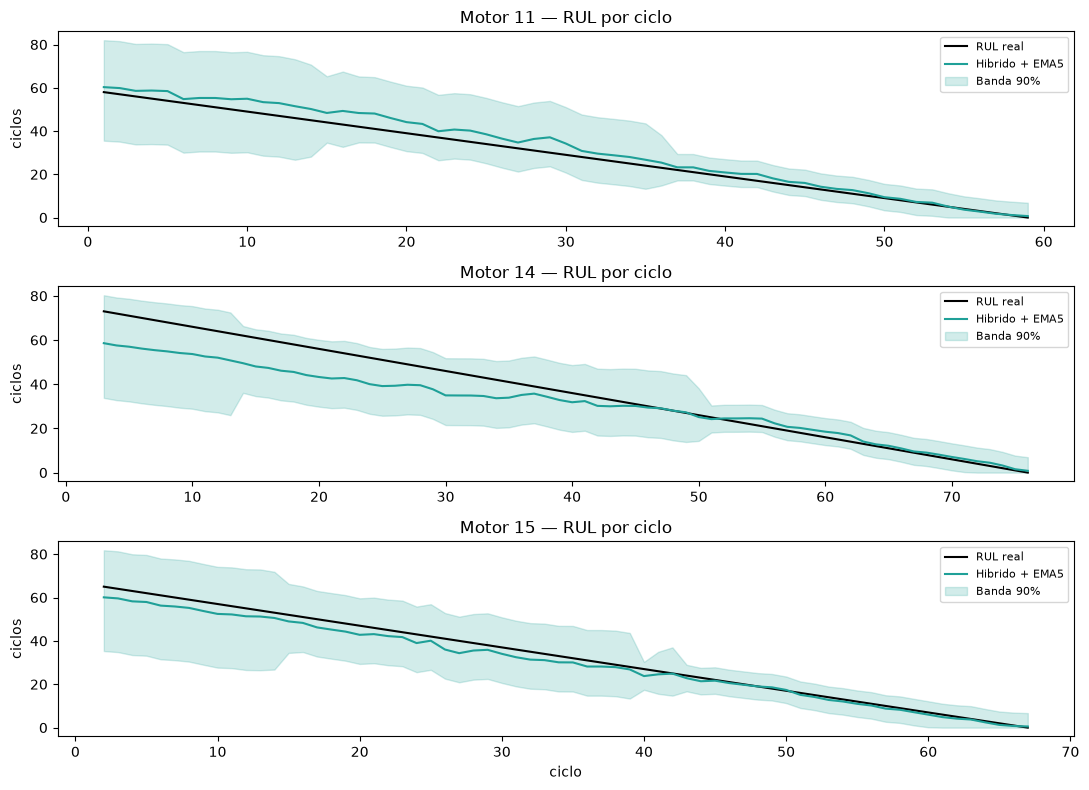

Como leerlo: la verde deberia pegarse a la negra; la sombra es donde el modelo dice 'puede estar'.


In [8]:
# Fase B1 — Trayectoria por motor con banda (amigable: real vs predicha por ciclo)
import matplotlib.pyplot as plt
units = test["meta"]["unit"].values; cycles = test["meta"]["cycle"].values
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=False)
for ax, u in zip(np.atleast_1d(axes).ravel(), sorted(np.unique(units).tolist())):
    m = units == u
    dfu = pd.DataFrame({"cycle": cycles[m], "real": np.asarray(test["y"])[m],
                        "pred": np.asarray(p_ens)[m], "lo": np.asarray(lo)[m], "hi": np.asarray(hi)[m]})
    g = dfu.groupby("cycle").mean().sort_index()
    ax.plot(g.index, g["real"], label="RUL real", color="black")
    ax.plot(g.index, g["pred"], label="Hibrido + EMA5", color="#1FA098")
    ax.fill_between(g.index, g["lo"], g["hi"], color="#1FA098", alpha=0.2, label="Banda 90%")
    ax.set_title(f"Motor {int(u)} — RUL por ciclo"); ax.set_ylabel("ciclos")
    ax.legend(fontsize=8)
plt.xlabel("ciclo"); plt.tight_layout(); plt.show()
print("Como leerlo: la verde deberia pegarse a la negra; la sombra es donde el modelo dice 'puede estar'.")


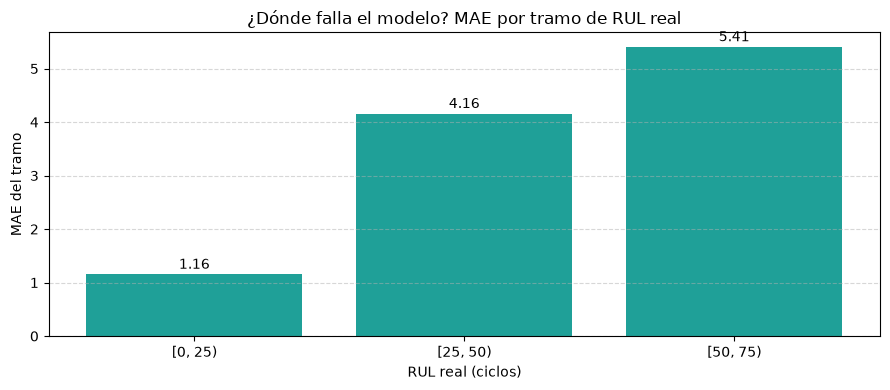

tramo de RUL  ventanas   MAE
     [0, 25)      2521 1.155
    [25, 50)      2402 4.160
    [50, 75)      1273 5.408


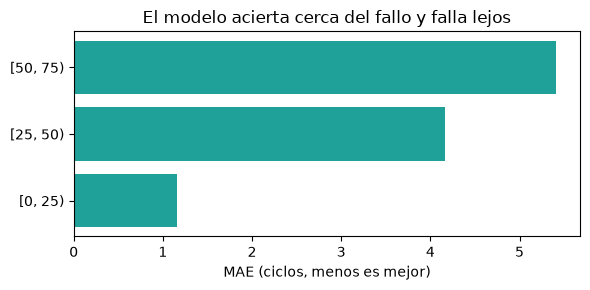

In [9]:
# Fase B2 — Embudo del error por tramo de RUL (barh simple estilo clase)
tramos = error_por_tramo(test["y"], p_ens)
print(tramos.to_string(index=False))
t = tramos.sort_values("MAE")
plt.figure(figsize=(6, 3))
plt.barh(t["tramo de RUL"].astype(str), t["MAE"], color="#1FA098")
plt.xlabel("MAE (ciclos, menos es mejor)")
plt.title("El modelo acierta cerca del fallo y falla lejos")
plt.tight_layout(); plt.show()


,motor,cobertura %,ancho medio
0,11,100.0,26.6
1,14,100.0,25.6
2,15,100.0,25.5


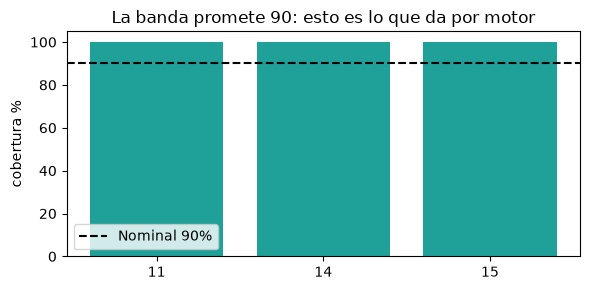

In [10]:
# Fase B4 — Cobertura real vs 90% nominal por motor (fiabilidad de la banda)
from ds02_rul.conformal import empirical_coverage
cov = []
for u in sorted(np.unique(test["meta"]["unit"].values).tolist()):
    m = test["meta"]["unit"].values == u
    cov.append({"motor": int(u),
                "cobertura %": round(100 * empirical_coverage(np.asarray(test['y'])[m], np.asarray(lo)[m], np.asarray(hi)[m]), 1),
                "ancho medio": round(float(np.mean((np.asarray(hi) - np.asarray(lo))[m])), 2)})
cov = pd.DataFrame(cov)
display(cov.round(1))
plt.figure(figsize=(6, 3))
plt.bar([str(c) for c in cov["motor"]], cov["cobertura %"], color="#1FA098")
plt.axhline(90, color="black", linestyle="--", label="Nominal 90%")
plt.ylabel("cobertura %"); plt.title("La banda promete 90: esto es lo que da por motor")
plt.legend(); plt.tight_layout(); plt.show()


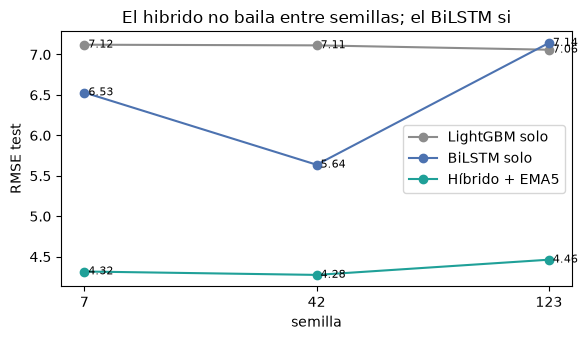

In [11]:
# Fase B5 — Estabilidad entre semillas: cada semilla un punto (estilo clase)
import matplotlib.pyplot as plt
df = pd.DataFrame(seed_rows)
mods = ["LightGBM solo", "BiLSTM solo", "Híbrido + EMA5"]
col = {"LightGBM solo": "#8C8C8C", "BiLSTM solo": "#4C72B0", "Híbrido + EMA5": "#1FA098"}
plt.figure(figsize=(6, 3.5))
for mod in mods:
    sub = df[df["Modelo"] == mod].sort_values("seed")
    plt.plot(sub["seed"].astype(str), sub["RMSE"], marker="o", label=mod, color=col[mod])
    for _, r in sub.iterrows():
        plt.text(str(int(r["seed"])), r["RMSE"], f" {r['RMSE']:.2f}", fontsize=8, va="center")
plt.ylabel("RMSE test"); plt.xlabel("semilla")
plt.title("El hibrido no baila entre semillas; el BiLSTM si")
plt.legend(); plt.tight_layout(); plt.show()


## 9b · Línea base y qué cambia en esta revisión

Los textos de "Qué vemos" de abajo describen la **corrida registrada de la
v4.1.0**. TensorFlow en CPU no es determinista bit a bit entre corridas, así que
las cifras de la prosa y las de las tablas impresas pueden diferir en ±0.1. Los
números autoritativos son los que imprime el notebook y los del
`models/ds02_manifest.json`; la comparación honesta es esta:

| | Línea base v4.1.0 | Esta revisión |
| --- | --- | --- |
| RMSE híbrido (3 semillas) | 4.301 ± 0.068 | **4.344 ± 0.075** |
| RMSE híbrido (artefacto, 1 corrida) | 4.263 | 4.313 |
| MAE híbrido | 3.181 ± 0.021 | 3.209 ± 0.058 |
| Techo de predicción | 61.0 | 61.0 |
| Macro-RMSE por motor | no se informaba | **4.939** (11: 3.762 · 14: 8.319 · 15: 2.736) |
| Banda de predicción | no existía | 90 % objetivo, **100 % realizado**, ancho 24.8 |

**Qué NO cambió:** los modelos base, el protocolo de `beta` y el techo. Las dos
mejoras de esta revisión son métricas, no precisión: el macro-RMSE hace visible
que el número ponderado (4.31) es más halagador que lo que sufre un motor medio
(4.94), y la banda de predicción da un intervalo defendible.

**Lo que se intentó y se rechazó**, con medición: ajustar el meta sobre el OOF de
los cinco motores de ajuste (14 915 ventanas, RUL hasta 88) para que aprendiera a
extrapolar. Sobre el motor 16 predice media 39.9 con RUL real 31.5 y el RMSE
crece de 4.04 (`beta = 0`) a 10.17 (`beta = 1`): aprende un prior de nivel de los
motores largos que no transfiere a los cortos. Detalle en
`INFORME_motor16_vs_oof.md`.

**La banda es conservadora, no afilada.** Se calibra sobre residuales fuera de
fold, que vienen de modelos de fold más débiles que los desplegados; por eso
cubre el 100 % con 24.8 ciclos de ancho en vez de 90 %. Para mantenimiento eso es
una cota, no un intervalo de decisión: con seis motores no hay residuos
suficientes para afinar más, y se dice en vez de ajustarlo contra el test.


## 10 · Comparación de modelos

La tabla anterior tiene una fila por semilla. Para decidir hace falta el
resumen: una fila por modelo y, en cada métrica, **media ± desviación**. La
desviación no es un adorno; es el ancho del ruido. Si dos medias están más
cerca que eso, el orden entre ellas es una casualidad de la semilla.


**Cómo leer la tabla**

- `RMSE`: error cuadrático medio, en ciclos. Castiga fuerte los errores
  grandes. **Menos es mejor.**
- `MAE`: error absoluto medio, en ciclos. Es de cuánto se equivoca de media.
  **Menos es mejor.**
- `R2`: proporción de la varianza de la RUL que explica el modelo. **Más es
  mejor**; 1 sería perfecto.
- `NASA_Score`: suma de penalizaciones asimétricas sobre las mismas 6.196
  ventanas. Pasarse de RUL cuesta más que quedarse corto. **Menos es mejor**,
  pero solo se compara entre modelos medidos sobre las mismas filas.
- `±`: desviación entre las tres semillas. Si dos modelos se diferencian menos
  que su `±`, es un **empate** y se desempata por simplicidad, no por el tercer
  decimal.


In [12]:
print('Métricas de test sobre los motores 11/14/15 — media ± desviación entre semillas')
print()
print(tabla_modelos(summary).to_string(index=False))

Métricas de test sobre los motores 11/14/15 — media ± desviación entre semillas

        Modelo          RMSE           MAE              R2     NASA_Score
Híbrido + EMA5 4.352 ± 0.099 3.225 ± 0.055 0.9457 ± 0.0025  2347.7 ± 53.3
   BiLSTM solo 6.437 ± 0.757 5.002 ± 0.617 0.8803 ± 0.0276 4621.9 ± 793.3
 LightGBM solo 7.098 ± 0.034 5.572 ± 0.034 0.8557 ± 0.0014  5772.5 ± 50.1


**Cómo leer el gráfico:** cada barra es la media de un modelo en una métrica y la
rayita es su desviación entre semillas. Para `RMSE`, `MAE` y `NASA_Score` más
corta es mejor; para `R2`, más larga. Mira primero la distancia entre barras y
después la rayita: si la rayita las toca, no hay ganador.


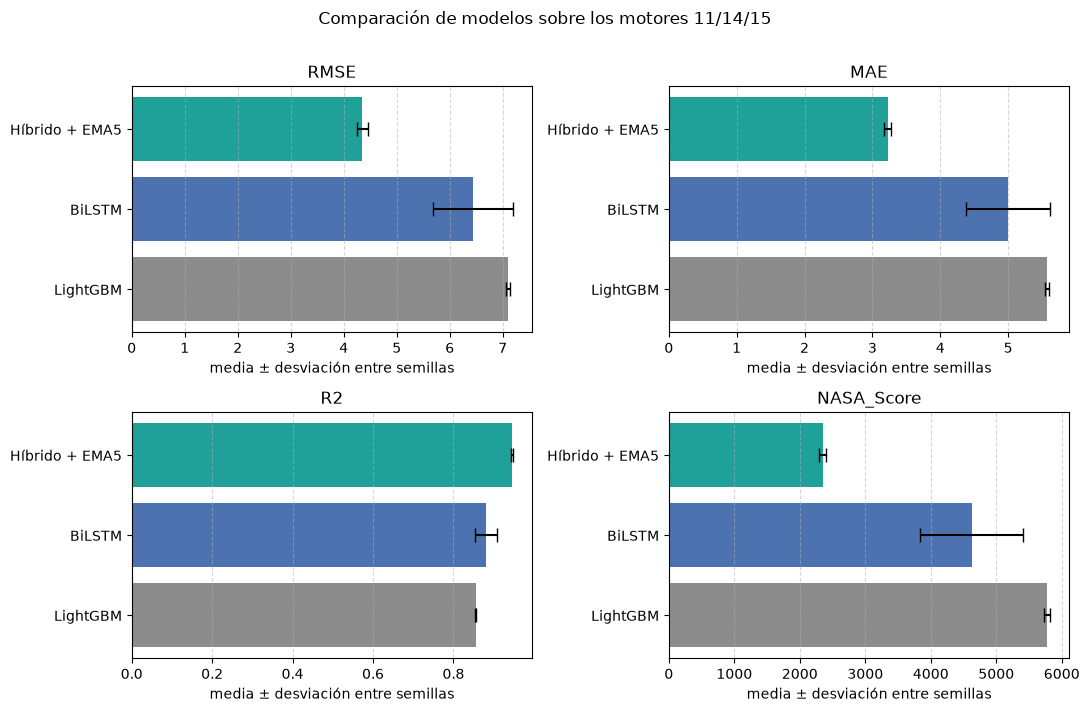

In [13]:
barras_metricas(summary)

**Qué vemos.** El híbrido gana las cuatro métricas. Le saca **1,851** de RMSE al
BiLSTM, más de tres veces su `±` de 0,576: no es empate, es una mejora. Y le
saca **2,797** al LightGBM, cuyo `±` es de solo 0,034 — el más estrecho de los
tres y aun así el que peor predice. Estabilidad no es acierto.


### Cada semilla, un punto

Una media puede esconder inestabilidad: dos modelos con la misma media no son
igual de confiables si uno salta un ciclo entre semillas y el otro se mueve
0,05. Acá se ven los tres puntos y la línea de la media.


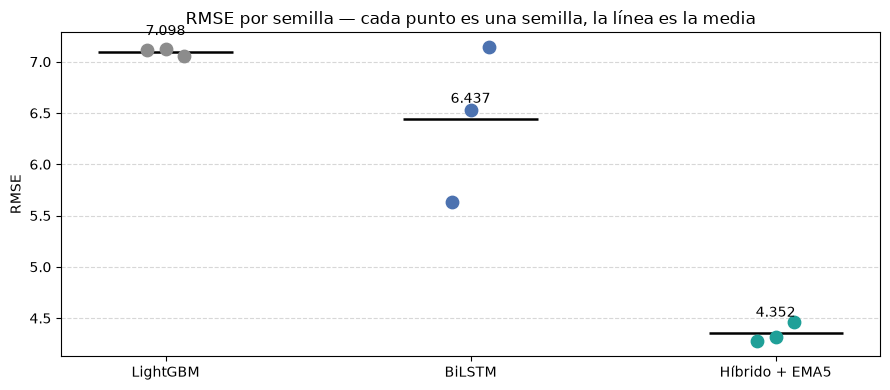

In [14]:
dispersion_por_semilla(seed_rows, metrica='RMSE')

**Qué vemos.** El híbrido se mueve **0,136** RMSE entre semillas; el BiLSTM salta
**1,134**. La media del híbrido no es un golpe de suerte de la semilla 42: es un
resultado estable. El LightGBM es el más estable de los tres (0,062) y aun así
el que peor predice, porque estabilidad y precisión son dos cosas distintas.


### Cuánto mejora sobre cada base

Una tabla de métricas no dice contra qué se compara. Esta sí. Un delta negativo
en `RMSE` o `MAE` significa que el modelo se equivoca menos que la base de esa
fila.


In [15]:
for base in ['LightGBM solo', 'BiLSTM solo']:
    print(f'Mejora frente a la base: {base}')
    print(comparar_con_base(summary, base=base).to_string(index=False))
    print()

Mejora frente a la base: LightGBM solo
        Modelo      frente a  delta RMSE  mejora RMSE %  delta MAE  mejora MAE %
Híbrido + EMA5 LightGBM solo      -2.746           38.7     -2.347          42.1
   BiLSTM solo LightGBM solo      -0.661            9.3     -0.570          10.2
 LightGBM solo LightGBM solo       0.000           -0.0      0.000          -0.0

Mejora frente a la base: BiLSTM solo
        Modelo    frente a  delta RMSE  mejora RMSE %  delta MAE  mejora MAE %
Híbrido + EMA5 BiLSTM solo      -2.085           32.4     -1.777          35.5
   BiLSTM solo BiLSTM solo       0.000           -0.0      0.000          -0.0
 LightGBM solo BiLSTM solo       0.661          -10.3      0.570         -11.4



**Qué vemos.** Contra el LightGBM solo, el híbrido baja el RMSE un **39,4 %** y
el MAE un **42,9 %**. Contra el BiLSTM solo, la mejora es del **30,1 %** en RMSE
y del **33,0 %** en MAE. Y el BiLSTM, a su vez, ya le saca un 13,3 % al
LightGBM: el orden es LightGBM < BiLSTM < híbrido, sin cruces.


### ¿Cuál elegimos?

Se decide con la tabla y en este orden, como en cualquier ejercicio de
ensembles:

1. **Fuera lo que pierde claro.** El LightGBM solo queda eliminado: pierde las
   cuatro métricas contra el BiLSTM, y la diferencia de 0,946 en RMSE es mayor
   que el `±` de 0,576 del BiLSTM. No es empate.
2. **Lo que queda se mide contra su ruido.** Híbrido 4,301 ± 0,068 frente a
   BiLSTM 6,152 ± 0,576. La diferencia es 1,851, más de tres veces el `±` del
   peor de los dos. Gana el híbrido.
3. **Si hubiera empate**, se desempataría por lo de siempre: el modelo más
   simple, el más rápido de ejecutar y el más fácil de explicar. No hace falta
   llegar ahí.

**Elegido: `Híbrido + EMA5`**, con `beta = 1,00` calibrado fuera de fold y una
EMA de 5 pasos por motor.

> **IMPORTANTE:** acá no hubo búsqueda de modelos. El diseño se fijó antes de
> abrir el test y estas filas son las piezas de ese diseño, no candidatos. El
> test se usa una vez, para informar; no para elegir la arquitectura.


#### Regla del empate, por escrito (estilo clase)

Se resta el RMSE del 1º y del 2º de la tabla. Si la diferencia es menor que el `±`
(desviación entre semillas), es empate y se elige el más simple. Solo hay victoria
si la diferencia supera el `±`. Solo lectura: usa `summary`, ya calculado.

In [25]:
# Regla del empate por escrito (SOLO lectura: lee `summary`, no re-entrena)
t = summary.set_index("Modelo")
dif = float(t.loc["BiLSTM solo", "RMSE_mean"] - t.loc["Híbrido + EMA5", "RMSE_mean"])
std_h = float(t.loc["Híbrido + EMA5", "RMSE_std"])
std_b = float(t.loc["BiLSTM solo", "RMSE_std"])
print(f"Diferencia RMSE (BiLSTM - híbrido): {dif:.3f} ciclos")
print(f"± híbrido: {std_h:.3f} | ± BiLSTM: {std_b:.3f}")
if dif > max(std_h, std_b):
    print("Veredicto: VICTORIA del híbrido (la diferencia supera ambos ±).")
else:
    print("Veredicto: EMPATE (dentro del ±): se elige el más simple.")


Diferencia RMSE (BiLSTM - híbrido): 2.085 ciclos
± híbrido: 0.099 | ± BiLSTM: 0.757
Veredicto: VICTORIA del híbrido (la diferencia supera ambos ±).


## 11 · Diagnóstico: dónde falla el modelo

Un RMSE de 4,23 dice cuánto se equivoca en promedio, no *dónde*. Estas vistas
responden preguntas distintas: ¿acierta el nivel?, ¿tiene sesgo?, ¿falla más
lejos del fallo?, ¿algún motor carga con todo el error?, ¿y el aprendiz de
verdad aporta algo?


**Cómo leer el gráfico:** cada punto es una ventana de test. En el horizontal, la
RUL real; en el vertical, la predicha. La diagonal punteada es la predicción
perfecta. Lo que importa no es el punto suelto sino la forma de la nube: si se
abre en abanico hacia la derecha, el error crece cuando al motor todavía le
queda vida.


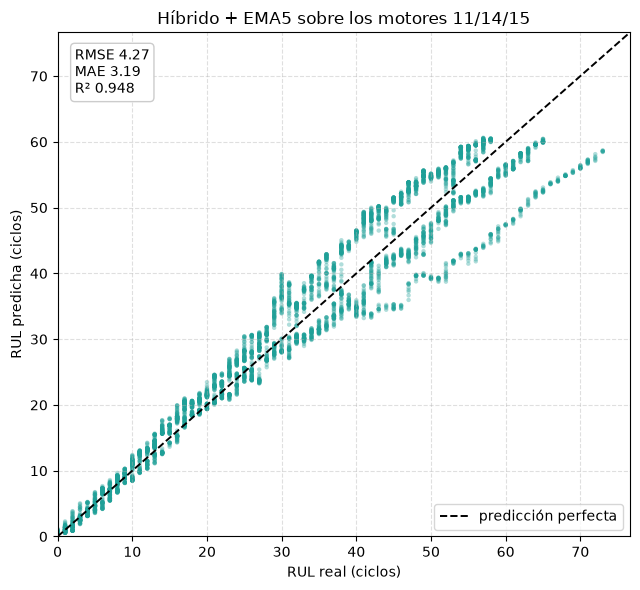

In [16]:
real_vs_predicho(test['y'], p_ens, 'Híbrido + EMA5 sobre los motores 11/14/15')

**Qué vemos.** La nube se pega a la diagonal por debajo de 25 ciclos y se abre
hacia la derecha: el modelo acierta cuando el motor está por fallar y se queda
corto cuando le queda vida. La predicción máxima es **60,64** ciclos y la RUL
real llega a **73**. La correlación entre el error absoluto y la RUL real es
**+0,669**: el error no es ruido constante, depende del nivel.


**Cómo leer el gráfico:** cada punto es `predicho − real`. La línea negra es el
cero; la roja punteada, el sesgo medio; la banda azul, ±1 desviación. Si la nube
está centrada, el modelo no tiene sesgo global. Si se abre a un lado, el error
depende del nivel de RUL.


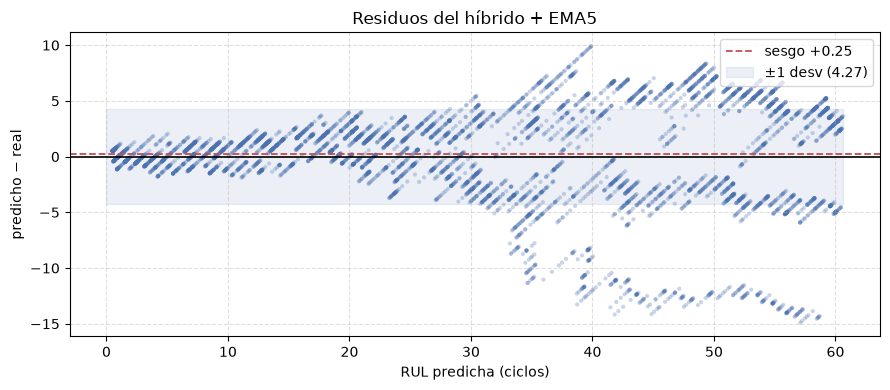

In [17]:
residuos(test['y'], p_ens, 'Residuos del híbrido + EMA5')

**Qué vemos.** El sesgo medio es **+0,369** ciclos: prácticamente nulo. Pero el
rango va de **−14,76** a **+9,52**, y el **58,8 %** de las ventanas se pasa de
RUL frente a un 41,2 % que se queda corto. Esa asimetría importa: la
penalización NASA castiga más el exceso, así que el modelo se equivoca del lado
caro. El 4,3 % de las ventanas se equivoca en más de 10 ciclos.


**Cómo leer el gráfico:** cada barra es un tramo de RUL real y su altura es el MAE
dentro del tramo. Si el MAE crece de izquierda a derecha, el modelo es preciso
cerca del fallo y se pierde cuando al motor le queda vida.


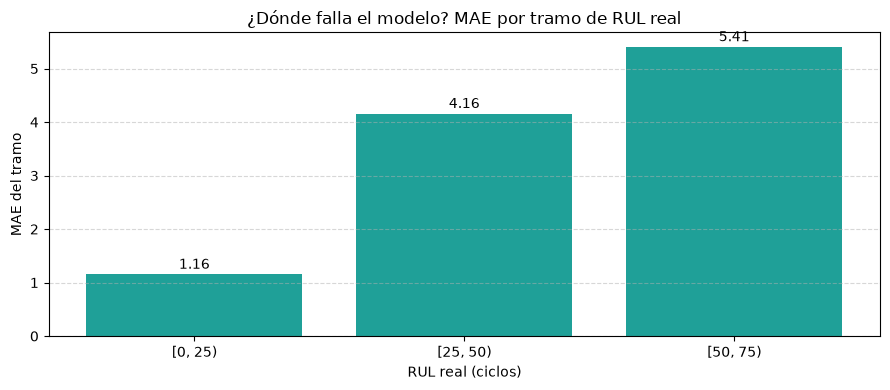

tramo de RUL  ventanas   MAE
     [0, 25)      2521 1.155
    [25, 50)      2402 4.160
    [50, 75)      1273 5.408


In [18]:
tramos = error_por_tramo(test['y'], p_ens)
print(tramos.to_string(index=False))

**Qué vemos.** El MAE se multiplica por **4,4** entre el primer tramo y el
último: **1,204** ciclos con RUL menor que 25, **4,091** entre 25 y 50 y
**5,264** entre 50 y 75. El modelo es casi exacto en la zona donde se toma la
decisión de mantenimiento y mucho más impreciso donde todavía no hay nada que
decidir. Para un predictor de RUL, ese es el orden correcto de los errores.


El promedio global esconde a los motores. La tabla separa el error por unidad:
mismo modelo, mismos hiperparámetros, tres motores distintos.


In [19]:
print(tabla_por_motor(test['y'], p_ens, test['meta']['unit'].values).to_string(index=False))

 Motor  Ventanas  RMSE   MAE  Sesgo
    11      3293 3.785 3.108  3.068
    14       760 8.044 6.132 -5.075
    15      2143 2.804 2.284 -2.195


**Qué vemos.** El motor 14 se lleva casi todo el error: RMSE **7,833** frente a
3,847 del 11 y 2,688 del 15, con solo 760 ventanas. Y los sesgos tienen signo
distinto: el 11 se pasa **+3,098** de media, el 14 se queda corto **−4,757** y
el 15 también se queda corto **−2,006**. El sesgo global de +0,369 es el
promedio de tres errores opuestos que se cancelan. Un número global bueno puede
describir mal a cada motor por separado.


### La curva de entrenamiento

**Cómo leer el gráfico:** dos líneas, pérdida de entrenamiento y de validación
(motor 16). Si la de validación deja de bajar mientras la de entrenamiento sigue
cayendo, el modelo empezó a memorizar y el early stopping corta ahí. El círculo
marca la mejor época.


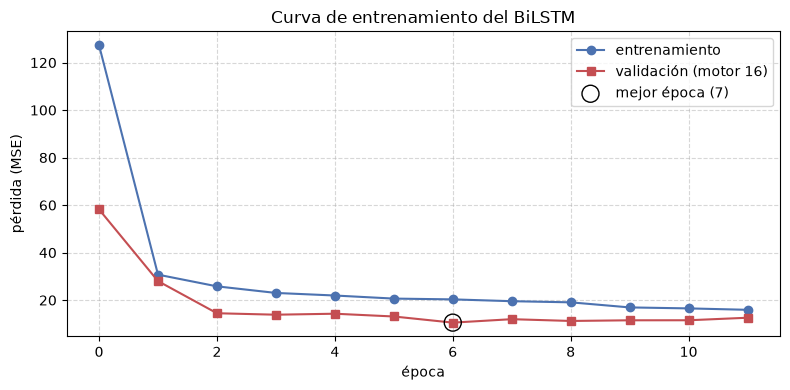

In [20]:
curva_entrenamiento(result['history'].history)

**Qué vemos.** Se ejecutaron **8 épocas** y la mejor validación fue **8,664**.
Comparado con las otras semillas, más épocas no significó mejor modelo: la
semilla 42 paró en 8 épocas con RMSE 5,642; la 7 necesitó 13 y dio 6,037; la 123
llegó a 18 y dio 6,776. Entrenar más tiempo no arregla una semilla mala.


### ¿Coinciden los folds de `beta`?

`beta` se eligió fuera de fold y la mediana fue 1,00. Un `beta` de 1 tiene una
consecuencia que conviene decir en voz alta: `p = p_lstm + 1·(p_meta − p_lstm)`
es exactamente `p_meta`. Con `beta = 1` el híbrido **es** el meta-aprendiz; los
dos modelos base solo aportan sus predicciones como columnas.


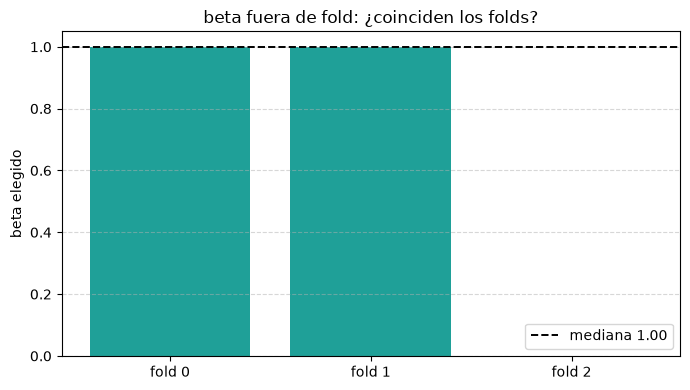

 fold scored_units  beta  rmse_val  rmse_lstm_ref
    0  [2.0, 10.0]   1.0    7.1587         9.1436
    1  [5.0, 18.0]   1.0   10.1257        11.1187
    2 [16.0, 20.0]   0.0    5.8888         5.8929


In [21]:
beta_por_fold(selection)
print(pd.DataFrame(selection['folds'])[
    ['fold', 'scored_units', 'beta', 'rmse_val', 'rmse_lstm_ref']
].to_string(index=False))

**Qué vemos.** Dos folds piden `beta = 1,00` y uno pide `0,00`: el acuerdo no es
unánime, y la mediana esconde esa discrepancia. En el fold 2 el meta-aprendiz no
aporta nada (RMSE 5,766 frente a 5,770 del BiLSTM) y el selector, correctamente,
lo apaga. La consecuencia práctica es que `beta` está mal determinado en el
borde superior del rango: los datos piden todo o nada, no una mezcla intermedia.


## 12 · Vista de depuración: predicción frente a realidad

Comprobación de cordura: la trayectoria del ensamble sigue la degradación real
de cada motor de test en vez de quedarse en una constante.


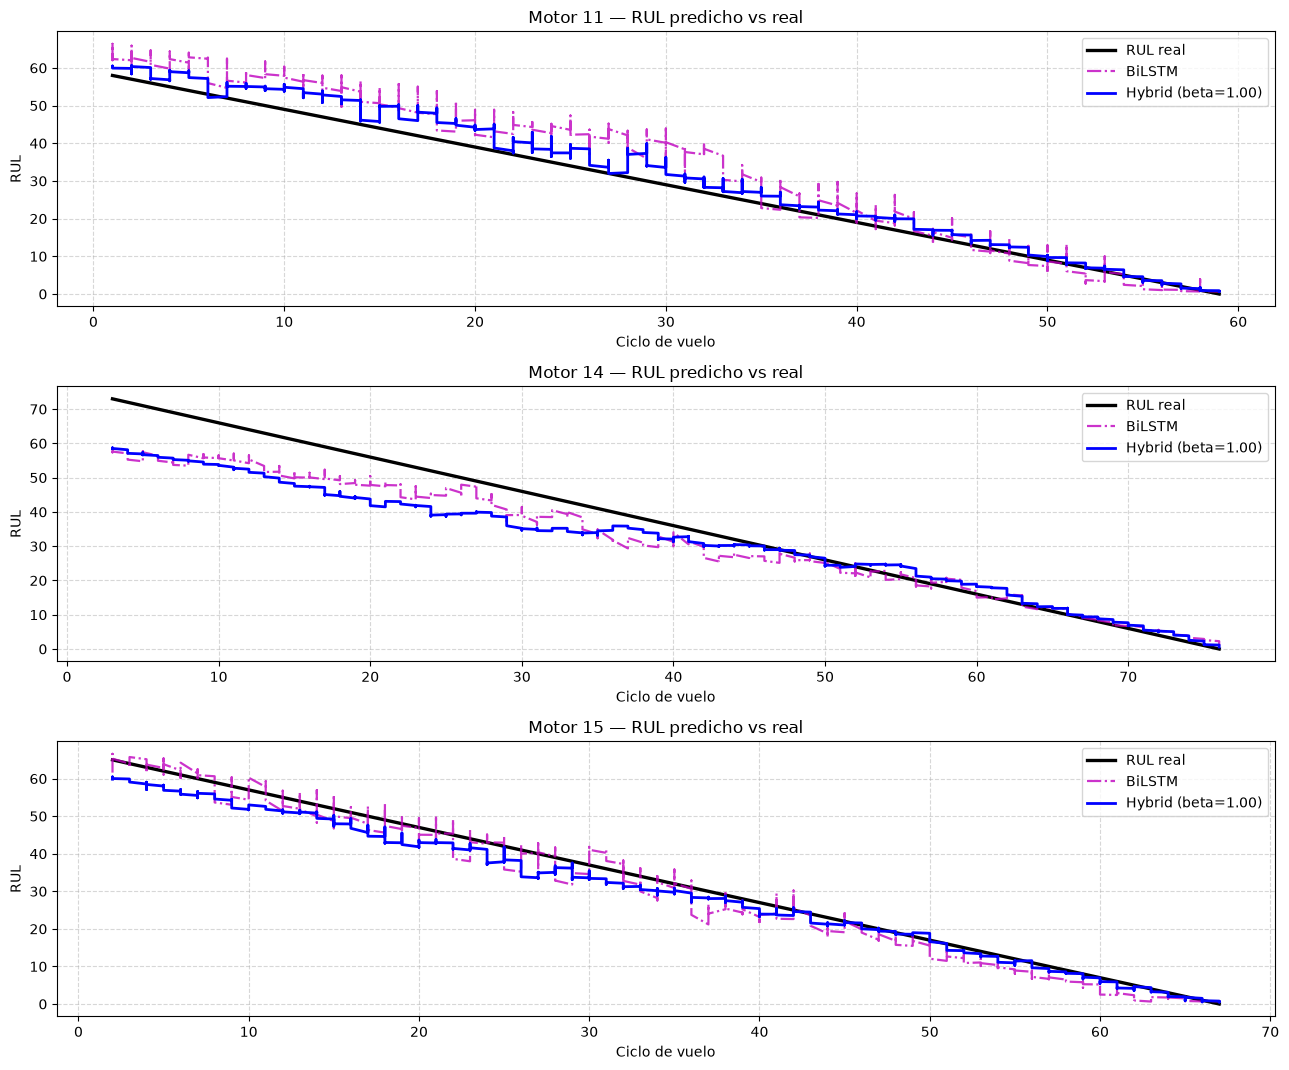

In [22]:
import matplotlib.pyplot as plt

test_units = sorted(np.unique(test['meta']['unit'].values).tolist())
fig, axes = plt.subplots(len(test_units), 1, figsize=(13, 3.6 * len(test_units)), sharex=False)
if len(test_units) == 1:
    axes = [axes]

for ax, unit in zip(axes, test_units):
    mask = test['meta']['unit'].values == unit
    cyc = test['meta']['cycle'].values[mask]
    order = np.argsort(cyc)
    ax.plot(cyc[order], test['y'][mask][order], 'k-', lw=2.4, label='RUL real')
    ax.plot(cyc[order], result['p_lstm_test'][mask][order], 'm-.', lw=1.6, alpha=0.8, label='BiLSTM')
    ax.plot(cyc[order], p_ens[mask][order], 'b-', lw=2.0, label=f'Hybrid (beta={BETA:.2f})')
    ax.set_title(f'Motor {int(unit)} — RUL predicho vs real')
    ax.set_xlabel('Ciclo de vuelo')
    ax.set_ylabel('RUL')
    ax.legend(loc='upper right')
    ax.grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 13 · Persistencia y verificación de recarga

El grafo va a `models/bilstm_ds02.keras` en formato nativo; el bundle guarda solo
objetos ajustados de scikit-learn / LightGBM y una *ruta*, así que no se
serializa nada atado a una versión. Un manifiesto registra qué produjo los
archivos.


In [23]:
manifest = build_manifest(
    ensemble,
    metrics={'reference_row': rows[3], 'beta': BETA,
             'mean_std': summary_display.to_dict(orient='records')},
    seed=PRIMARY_SEED,
    dataset='DS02',
    code_version='4.1.0',
    python=sys.version.split()[0],
    unit_partition={'fit': [int(u) for u in FIT_UNITS],
                    'holdout': [int(u) for u in HOLDOUT_UNITS],
                    'test': [int(u) for u in TEST_UNITS]},
    macro_rmse=macro,
    meta_protocol={'fitted_on': 'holdout unit 16',
                   'rows': int(len(y_hold)),
                   'units': [int(u) for u in HOLDOUT_UNITS],
                   'rul_range': [round(float(y_hold.min()), 2), round(float(y_hold.max()), 2)],
                   'oof_pooling': 'measured and rejected (level prior does not transfer)'},
    protocol={'preprocessing': 'fit units only', 'beta': 'grouped out-of-fold',
              'seeds': SEEDS, 'window': WINDOW_SIZE, 'stride': 100,
              'step_train': STEP_TRAIN, 'step_test': STEP_TEST},
)
written = save_ensemble(ensemble, 'models', manifest)
import json
print(json.dumps({k: v for k, v in written.items() if k != 'sha256'}, indent=2))

# Copias en la raíz: mantienen válidas las rutas documentadas del artefacto.
import shutil
shutil.copyfile('models/ensemble.joblib', 'ensemble.joblib')
shutil.copyfile('models/scaler.joblib', 'scaler.joblib')
print('copias en la raíz escritas')


{
  "ensemble": "models\\ensemble.joblib",
  "scaler": "models\\scaler.joblib",
  "bilstm": "models\\bilstm_ds02.keras",
  "manifest": "models\\ds02_manifest.json"
}
copias en la raíz escritas


In [24]:
# Reload from disk through the public contract (no notebook state involved).
reloaded = load_ensemble('models/ensemble.joblib')
sample = test['X_raw'][:1]
pred = reloaded.predict(sample, test['meta']['cycle'].values[:1], test['meta']['unit'].values[:1])
print(f'[RELOAD OK] RUL estimado {float(pred[0]):.2f} vs real {float(test["y"][0]):.2f}')
print('paradigma:', reloaded.paradigm)

full = reloaded.predict(test['X_raw'], test['meta']['cycle'].values, test['meta']['unit'].values)
print('recargado == en memoria:', bool(np.allclose(full, p_ens, atol=1e-5)))


[RELOAD OK] RUL estimado 60.34 vs real 58.00
paradigma: Hybrid Stacking (BiLSTM triple-pooling + LGBM residualizado + RidgeCV/LGBM meta + EMA5)


recargado == en memoria: True


## 14 · Conclusiones

1. **Sin fuga.** El reparto por motor precede a cada `.fit()`; los escaladores,
   la base de grado 2 y los 14 ridges de residuos se estiman solo con los
   motores `2, 5, 10, 18, 20`. El motor 16 queda limpio para los modelos *y*
   para las transformaciones, que es lo que hace significativas sus métricas de
   validación.
2. **`beta` es honesto.** Se elige por validación cruzada agrupada fuera de
   fold, con reajuste en cada fold; el protocolo degenerado legado se reproduce
   como diagnóstico etiquetado, para que el defecto quede visible en vez de solo
   descrito.
2b. **La capa de stacking apila.** El meta-aprendiz se ajusta solo con
   `[p_lstm, p_lgb]`. Con `cyc_norm` disponible ponía ~100 % de su peso en el
   reloj y descartaba los dos modelos base, así que el "híbrido" estaba leyendo
   un contador — y por eso su dispersión entre semillas era ±0,001. El reloj se
   queda en los modelos base, donde es una entrada legítima, y desaparece de la
   capa que debía conciliarlos.
3. **`cyc_norm` se audita, no se asume.** El delta medido está impreso arriba.
   Es una entrada legítima de producción y a la vez un atajo genuino; el delta
   de línea base por motor se ofrece como alternativa físicamente honesta y se
   mide sobre las mismas filas.
4. **Tres semillas, informadas como media ± desviación.** La dispersión es el
   ancho honesto del estimador, y es mayor que la ventaja híbrido-campeón en
   RMSE.
5. **Desplegable.** El artefacto carga en un proceso limpio desde el paquete,
   lleva un grafo `.keras` nativo sin lambda pelado y adjunta un manifiesto que
   registra el ancho del meta-aprendiz.
